In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import h5py
import math
import cv2
import torch
from snntorch import spikegen
import os
from skimage import transform
from lightglue import viz2d
from lightglue import LightGlue, SuperPoint, DISK
from lightglue.utils import numpy_image_to_torch, rbd
from pathlib import Path
from ultralytics import YOLO
import matplotlib.patches as patches

### Select candidate frames for homography

In [2]:
def spatial_entropy(frame, grid=(3, 4), normalize=True):
    frame = np.asarray(frame)
    h, w = frame.shape
    gh, gw = grid

    ys = np.linspace(0, h, gh + 1, dtype=int)
    xs = np.linspace(0, w, gw + 1, dtype=int)

    # sum activity in each cell
    cell_counts = []
    for i in range(gh):
        for j in range(gw):
            cell = frame[ys[i]:ys[i+1], xs[j]:xs[j+1]]
            cell_counts.append(cell.sum())

    cell_counts = np.asarray(cell_counts, dtype=float)
    total = cell_counts.sum()

    if total == 0:
        return 0.0, cell_counts

    # probability distribution over cells
    p = cell_counts / total
    p = p[p > 0]  # avoid log(0)

    H = -(p * np.log2(p)).sum()

    if normalize:
        H_max = np.log2(gh * gw)
        H = H / H_max if H_max > 0 else 0.0

    return float(H), cell_counts

In [3]:
clip_dir = "//172.16.222.2/tmp/Nora/traffic_flow_data/week_31/box_1/2024_07_31_16_54_30_recordings/event_frames"
clip_path= os.path.join(clip_dir, "clip_000_frames.h5")

with h5py.File(clip_path, "r") as f:
    frames = f["frames"][:]

activity = frames.reshape(frames.shape[0], -1).sum(axis=1)

In [4]:
candidates = []

for i in range(len(frames)):
    a = activity[i]/frames[0].size
    if  a > 0.05:
        entropy, counts = spatial_entropy(frames[i], (3, 4))
        if entropy > 0.85:
            candidates.append({"frame": frames[i], "idx": i, "activity": a, "entropy": entropy})

print(f"Found {len(candidates)} candidate frames")

Found 55 candidate frames


In [11]:
# Search for clip
found_candidates = 0
clip_idx = 0

while found_candidates < 100:
    clip_path = os.path.join(clip_dir, f"clip_{clip_idx:03d}_frames.h5")

    with h5py.File(clip_path, "r") as f:
        frames = f["frames"][:]

    activity = frames.reshape(frames.shape[0], -1).sum(axis=1)

    candidates = []

    for i in range(len(frames)):
        a = activity[i]/frames[0].size
        if  a > 0.05:
            entropy, counts = spatial_entropy(frames[i], (3, 4))
            if entropy > 0.85:
                candidates.append({"frame": frames[i], "idx": i, "activity": a, "entropy": entropy})

    print(f"Found {len(candidates)} candidate frames in clip_{clip_idx:03d}")
    found_candidates = len(candidates)
    clip_idx += 1

Found 55 candidate frames in clip_000
Found 0 candidate frames in clip_001
Found 0 candidate frames in clip_002
Found 0 candidate frames in clip_003
Found 0 candidate frames in clip_004
Found 0 candidate frames in clip_005
Found 0 candidate frames in clip_006
Found 0 candidate frames in clip_007
Found 0 candidate frames in clip_008
Found 0 candidate frames in clip_009
Found 0 candidate frames in clip_010
Found 0 candidate frames in clip_011
Found 0 candidate frames in clip_012
Found 0 candidate frames in clip_013
Found 0 candidate frames in clip_014
Found 0 candidate frames in clip_015
Found 0 candidate frames in clip_016
Found 0 candidate frames in clip_017
Found 0 candidate frames in clip_018
Found 0 candidate frames in clip_019
Found 0 candidate frames in clip_020
Found 0 candidate frames in clip_021
Found 0 candidate frames in clip_022
Found 0 candidate frames in clip_023
Found 0 candidate frames in clip_024
Found 0 candidate frames in clip_025
Found 0 candidate frames in clip_026


FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '//172.16.222.2/tmp/Nora/traffic_flow_data/week_31/box_1/2024_07_31_16_54_30_recordings/event_frames\clip_170_frames.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

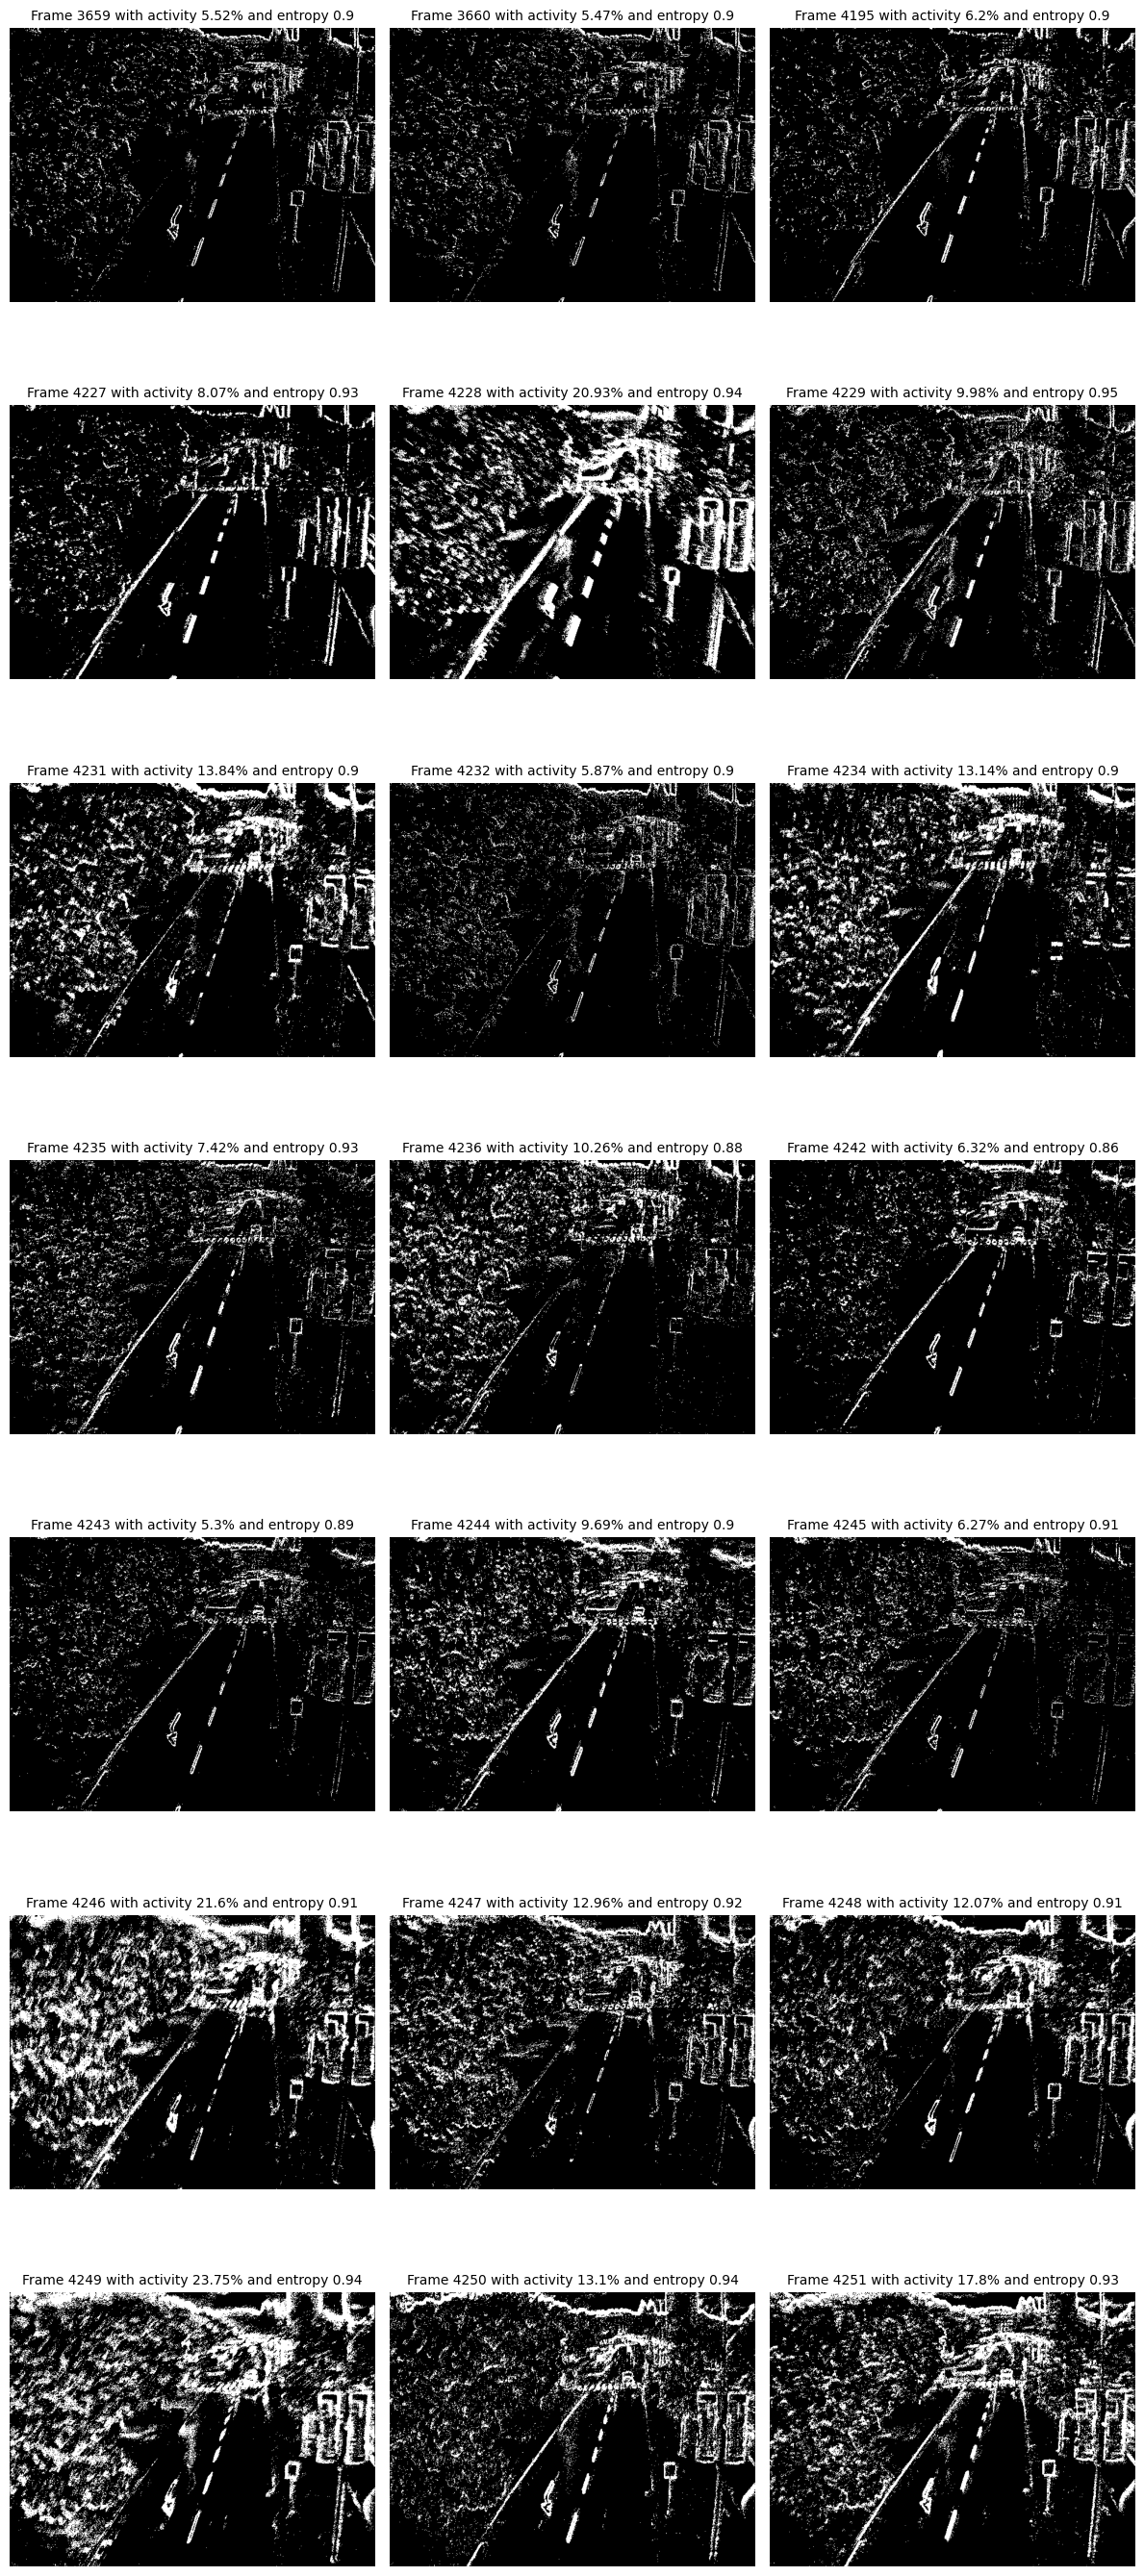

In [5]:
n = len(candidates)
cols = 3
n = np.min((21,n))
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))

axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i in range(rows * cols):
    ax = axes[i]

    if i < n:
        fm = candidates[i]
        ax.imshow(fm["frame"], cmap='gray')
        ax.set_title(f"Frame {fm['idx']} with activity {round(fm['activity']*100,2)}% and entropy {round(fm['entropy'],2)}", fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [6]:
k = 10

top_candidates = sorted(candidates, key=lambda x: x["activity"], reverse=True)[:10]
top_indices = [c["idx"] for c in top_candidates]
top_activity = [c["activity"] for c in top_candidates]
top_frames = [c["frame"] for c in top_candidates]

In [7]:
c = 1
for i in range(len(top_candidates)):
    entropy, counts = spatial_entropy(top_frames[i], (16, 16))
    print(f"{c}. Activity: {round(counts.sum()/top_frames[i].size*100, 2)}%, Entropy: {round(entropy,3)}, Frame nbr: {top_indices[i]}")
    c += 1

1. Activity: 23.75%, Entropy: 0.936, Frame nbr: 4249
2. Activity: 21.6%, Entropy: 0.925, Frame nbr: 4246
3. Activity: 20.93%, Entropy: 0.931, Frame nbr: 4228
4. Activity: 17.8%, Entropy: 0.929, Frame nbr: 4251
5. Activity: 15.01%, Entropy: 0.914, Frame nbr: 4253
6. Activity: 13.84%, Entropy: 0.915, Frame nbr: 4231
7. Activity: 13.14%, Entropy: 0.916, Frame nbr: 4234
8. Activity: 13.1%, Entropy: 0.927, Frame nbr: 4250
9. Activity: 12.96%, Entropy: 0.925, Frame nbr: 4247
10. Activity: 12.07%, Entropy: 0.914, Frame nbr: 4248


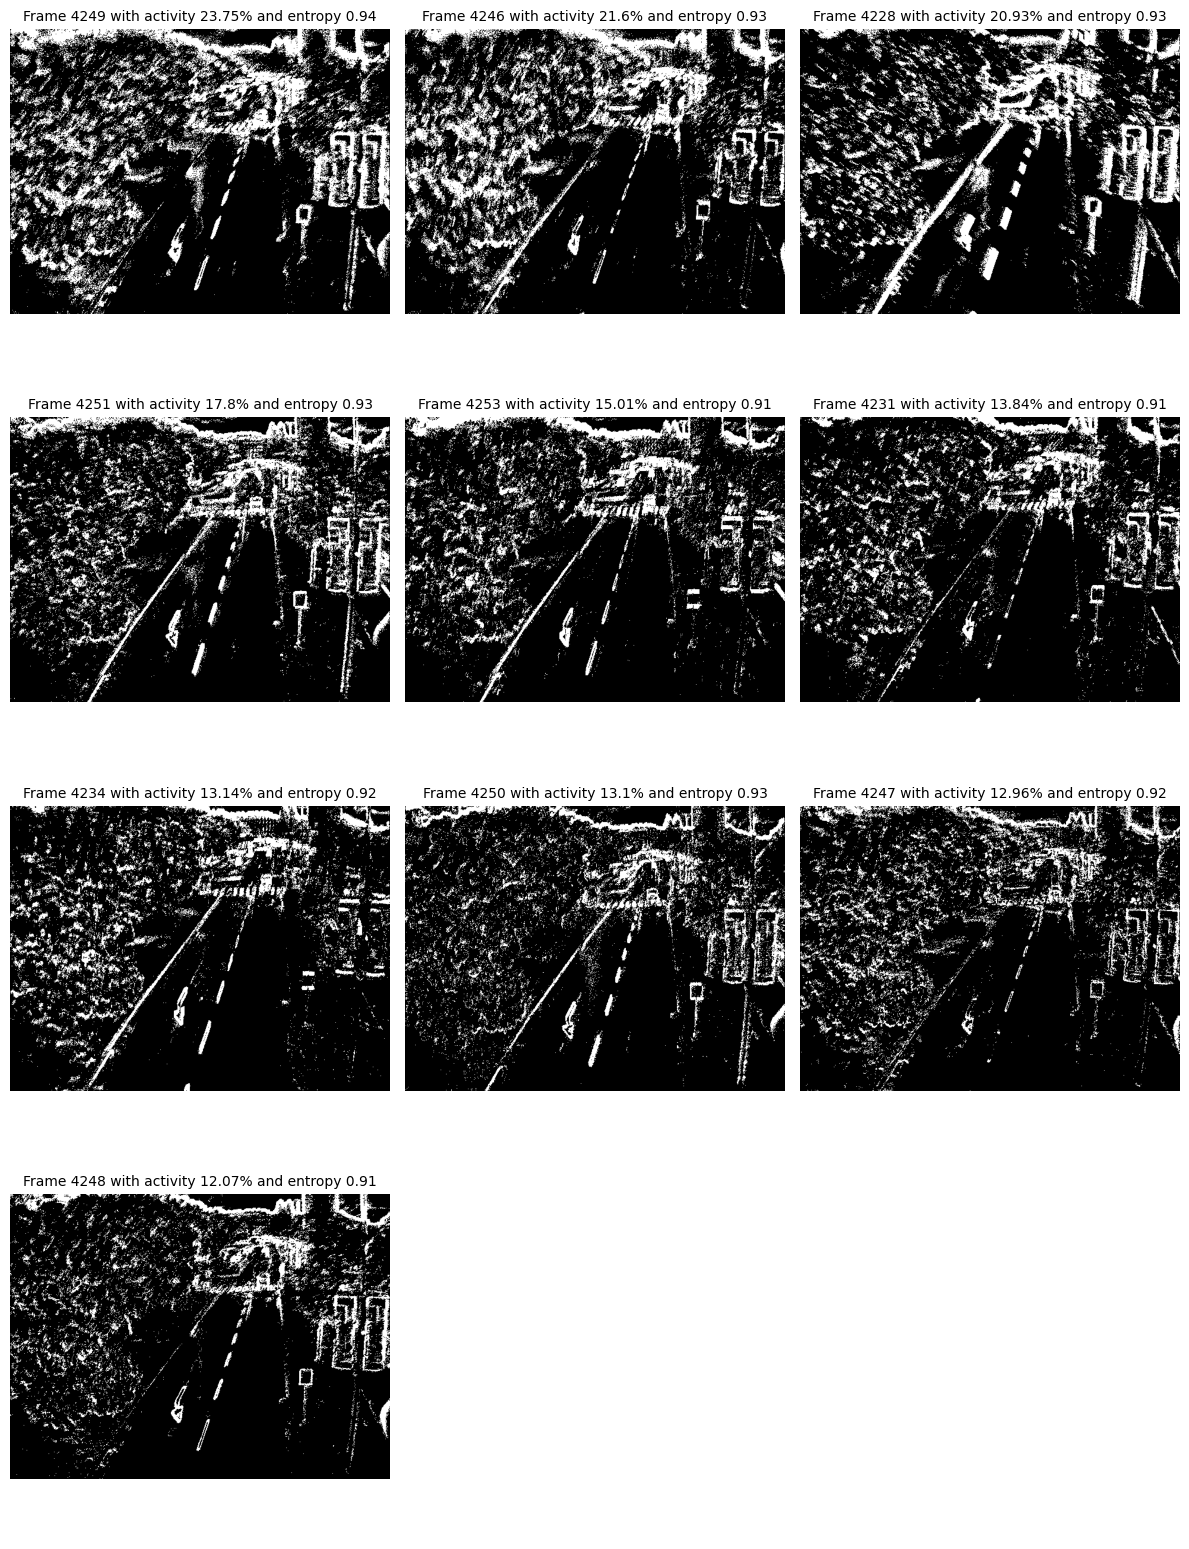

In [8]:
n = len(top_indices)
cols = 3
n = np.min((21,n))
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))

axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i in range(rows * cols):
    ax = axes[i]

    if i < n:
        entropy, counts = spatial_entropy(top_frames[i], (16, 16))
        ax.imshow(top_frames[i], cmap='gray')
        ax.set_title(f"Frame {top_indices[i]} with activity {round(counts.sum()/frames[0].size*100, 2)}% and entropy {round(entropy,2)}", fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

### Test build homography for evaluation

In [31]:
video_path = "//172.16.222.2/EBVrecordings/2024-TrafficMonitoring/data_collection/week_31/box_1/2024_07_31_16_54_30_recordings/video.avi"
timestamp_path = "//172.16.222.2/EBVrecordings/2024-TrafficMonitoring/data_collection/week_31/box_1/2024_07_31_16_54_30_recordings/timestamps.csv"
out_path = "//172.16.222.2/tmp/Nora/traffic_flow_data/week_31/box_1/2024_07_31_16_54_30_recordings/homography.npz"

In [10]:
df_timestamps = pd.read_csv(timestamp_path)
SHIFT = df_timestamps.index[df_timestamps["event_time"] != 0][0]

In [11]:
cfg = {
    "extractor": "SuperPoint",
    "device": "cpu",   # change to "cuda" if available
    "max_kpts": 4096,
    "homography": {
        "method": cv2.RANSAC,
        "ransacReprojThreshold": 3.0,
    }
}

In [12]:
def extract_clip_id(filename: str):
    # Extract clip id like 'clip_000' from filename
    m = re.search(r"(clip_\d{3})", filename)
    return m.group(1) if m else None


def event_to_gray_uint8(img):
    img = np.asarray(img, np.float32)
    img -= img.min()
    mx = img.max()
    if mx > 0:
        img *= 255.0 / mx
    return img.astype(np.uint8)


def load_frame(path: str):
    ext = os.path.splitext(path)[1].lower()

    if ext == ".npy":
        return np.load(path)

    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None:
        raise RuntimeError(f"Could not read file: {path}")

    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    return img


def preprocess_lightglue(img):
    img = event_to_gray_uint8(img)
    return numpy_image_to_torch(img)


def build_lightglue_models(cfg):
    device = cfg["device"]

    if cfg["extractor"] == "SuperPoint":
        extractor = SuperPoint(max_num_keypoints=cfg["max_kpts"]).eval().to(device)
        matcher = LightGlue(features="superpoint").eval().to(device)
    elif cfg["extractor"] == "DISK":
        extractor = DISK(max_num_keypoints=cfg["max_kpts"]).eval().to(device)
        matcher = LightGlue(features="disk").eval().to(device)
    else:
        raise ValueError(f"Unknown extractor: {cfg['extractor']}")

    return extractor, matcher


@torch.inference_mode()
def match_lightglue(img0, img1, extractor, matcher, device="cpu"):
    img0 = preprocess_lightglue(img0).to(device)
    img1 = preprocess_lightglue(img1).to(device)

    feats0 = extractor.extract(img0)
    feats1 = extractor.extract(img1)

    matches01 = matcher({"image0": feats0, "image1": feats1})
    feats0, feats1, matches01 = [rbd(x) for x in [feats0, feats1, matches01]]

    kpts0 = feats0["keypoints"]
    kpts1 = feats1["keypoints"]
    matches = matches01["matches"]

    points0 = kpts0[matches[:, 0]]
    points1 = kpts1[matches[:, 1]]

    return {
        "points0": points0,
        "points1": points1,
        "matches": matches,
        "kpts0": kpts0,
        "kpts1": kpts1,
        "matches01": matches01,
    }

def visualize_lightglue(img0, img1, points0, points1, kpts0, kpts1, matches01, **kwargs):
    axes = viz2d.plot_images([img0, img1])
    viz2d.plot_matches(points0, points1, color='lime', lw=0.2)
    viz2d.add_text(0, f'Stop after {matches01["stop"]} layers', fs=20)

    kpc0, kpc1 = viz2d.cm_prune(matches01['prune0']), viz2d.cm_prune(matches01['prune1'])
    viz2d.plot_images([img0, img1])
    viz2d.plot_keypoints([kpts0, kpts1], colors=[kpc0, kpc1], ps=10)


def homography_from_matches(results, cfg):
    pts0 = results["points0"]
    pts1 = results["points1"]

    if torch.is_tensor(pts0):
        pts0 = pts0.detach().cpu().numpy()
    if torch.is_tensor(pts1):
        pts1 = pts1.detach().cpu().numpy()

    pts0 = np.asarray(pts0, dtype=np.float32).reshape(-1, 2)
    pts1 = np.asarray(pts1, dtype=np.float32).reshape(-1, 2)

    if len(pts0) < 4:
        return None, None, pts0, pts1

    H, mask = cv2.findHomography(
        pts0,
        pts1,
        method=cfg["homography"]["method"],
        ransacReprojThreshold=cfg["homography"]["ransacReprojThreshold"],
    )
    return H, mask, pts0, pts1

def collect_pairs_by_clip(proxy_dir, event_dir):
    proxy_by_clip = {}
    event_by_clip = {}

    for f in os.listdir(proxy_dir):
        full = os.path.join(proxy_dir, f)
        if not os.path.isfile(full):
            continue
        clip_id = extract_clip_id(f)
        if clip_id is None:
            continue
        proxy_by_clip.setdefault(clip_id, []).append(full)

    for f in os.listdir(event_dir):
        full = os.path.join(event_dir, f)
        if not os.path.isfile(full):
            continue
        clip_id = extract_clip_id(f)
        if clip_id is None:
            continue
        event_by_clip.setdefault(clip_id, []).append(full)

    common_clips = sorted(
        set(proxy_by_clip.keys()) & set(event_by_clip.keys()),
        key=lambda x: int(re.search(r"\d+", x).group())
    )

    pairs = []
    for clip_id in common_clips:
        proxy_files = sorted(proxy_by_clip[clip_id])
        event_files = sorted(event_by_clip[clip_id])

        if len(proxy_files) != 1:
            print(f"Skipping {clip_id}: expected 1 proxy frame, found {len(proxy_files)}")
            continue

        if len(event_files) != 1:
            print(f"Skipping {clip_id}: expected 1 extracted event frame, found {len(event_files)}")
            continue

        pairs.append((clip_id, proxy_files[0], event_files[0]))

    return pairs

In [13]:
candidate_idx = [candidate["idx"] for candidate in candidates]

In [14]:
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {video_path}")

top_set = set(int(i) for i in candidate_idx)

spike_dict = {}
counter = 0

ret, frame = cap.read()
if not ret:
    raise RuntimeError("Empty video")

prev_gray = None
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY).astype(np.float32)

t = 0

while t < (SHIFT + 5400*0):
    ret, frame = cap.read()
    t += 1

i = 0

while True:
    ret, next_frame = cap.read()
    if not ret:
        break

    next_gray = cv2.cvtColor(next_frame, cv2.COLOR_BGR2GRAY).astype(np.float32)

    if i in top_set:

        if prev_gray is None:
            counter += 1
        else:
            data = torch.from_numpy(
                np.stack([prev_gray, gray, next_gray], axis=0)
            ).to(torch.float32)

            spikes = spikegen.delta(data, threshold=8)
            sp = spikes[1:].cpu().numpy() if torch.is_tensor(spikes) else spikes

            spike_dict[i] = (sp > 0).any(axis=0).astype(np.uint8)
        
        counter += 1

        if counter == len(top_set):
            break

    # Shift window forward
    prev_gray = gray
    gray = next_gray
    frame = next_frame
    i += 1

cap.release()

In [15]:
extractor, matcher = build_lightglue_models(cfg)

In [16]:
for idx in top_indices:
    print(f"Processing {idx}")

    proxy_img = event_to_gray_uint8(spike_dict[idx])
    event_img = event_to_gray_uint8(frames[idx])

    results = match_lightglue(
        proxy_img,
        event_img,
        extractor=extractor,
        matcher=matcher,
        device=cfg["device"],
    )

    print(f"matches={len(results['matches'])}, out of total features={results['kpts1'].shape[0]}")

Processing 4249
matches=787, out of total features=2809
Processing 4246
matches=906, out of total features=2800
Processing 4228
matches=589, out of total features=3075
Processing 4251
matches=784, out of total features=3023
Processing 4253
matches=888, out of total features=2963
Processing 4231
matches=940, out of total features=3052
Processing 4234
matches=764, out of total features=2975
Processing 4250
matches=744, out of total features=3153
Processing 4247
matches=761, out of total features=2898
Processing 4248
matches=903, out of total features=2990


In [17]:
sel_idx = 4231

In [18]:
proxy_img = event_to_gray_uint8(spike_dict[sel_idx])
event_img = event_to_gray_uint8(frames[sel_idx])

results = match_lightglue(
    proxy_img,
    event_img,
    extractor=extractor,
    matcher=matcher,
    device=cfg["device"],
)

H, mask, pts0, pts1 = homography_from_matches(results, cfg)

num_matches = len(pts0)
num_inliers = 0 if mask is None else int(mask.ravel().sum())
ok = H is not None

print(f"  matches={num_matches}, inliers={num_inliers}, homography_ok={ok}")

  matches=940, inliers=415, homography_ok=True


In [32]:
np.savez_compressed(
        out_path,
        H=np.array([]) if H is None else H.astype(np.float32),
        inlier_mask=np.array([]) if mask is None else mask.astype(np.uint8),
        points0=pts0.astype(np.float32),
        points1=pts1.astype(np.float32),
        num_matches=np.array([len(pts0)], dtype=np.int32),
        num_inliers=np.array([0 if mask is None else int(mask.ravel().sum())], dtype=np.int32),
        H1=frames[sel_idx].shape[0],
        W1=frames[sel_idx].shape[1],
        H2=spike_dict[sel_idx].shape[0],
        W2=spike_dict[sel_idx].shape[1]
    )

## Visualization
Not necessary to run

In [19]:
all_points0 = []
all_points1 = []

for idx in candidate_idx:
    print(f"Processing {idx}")

    proxy_img = event_to_gray_uint8(spike_dict[idx])
    event_img = event_to_gray_uint8(frames[idx])

    results = match_lightglue(
        proxy_img,
        event_img,
        extractor=extractor,
        matcher=matcher,
        device=cfg["device"],
    )

    n_matches = len(results["matches"])
    print(f"matches={n_matches}, out of total features={results['kpts1'].shape[0]}")

    all_points0.append(results["points0"])
    all_points1.append(results["points1"])

all_points0 = torch.cat(all_points0, dim=0) if torch.is_tensor(all_points0[0]) else np.concatenate(all_points0, axis=0)
all_points1 = torch.cat(all_points1, dim=0) if torch.is_tensor(all_points1[0]) else np.concatenate(all_points1, axis=0)

combined_results = {"points0": all_points0, "points1": all_points1}

H, mask, pts0, pts1 = homography_from_matches(combined_results, cfg)

print("Total concatenated matches:", len(pts0))
print("Estimated H:\n", H)

num_matches = len(pts0)
num_inliers = 0 if mask is None else int(mask.ravel().sum())
ok = H is not None

print(f"  matches={num_matches}, inliers={num_inliers}, homography_ok={ok}")

Processing 3659
matches=413, out of total features=2547
Processing 3660
matches=453, out of total features=2664
Processing 4195
matches=652, out of total features=2362
Processing 4227
matches=326, out of total features=2444
Processing 4228
matches=589, out of total features=3075
Processing 4229
matches=262, out of total features=3176
Processing 4231
matches=940, out of total features=3052
Processing 4232
matches=688, out of total features=2928
Processing 4234
matches=764, out of total features=2975
Processing 4235
matches=715, out of total features=2930
Processing 4236
matches=691, out of total features=2849
Processing 4242
matches=503, out of total features=2344
Processing 4243
matches=676, out of total features=2447
Processing 4244
matches=449, out of total features=2734
Processing 4245
matches=364, out of total features=2686
Processing 4246
matches=906, out of total features=2800
Processing 4247
matches=761, out of total features=2898
Processing 4248
matches=903, out of total featur

In [22]:
def visualize_matches_on_event(event_img, pts0, pts1, H=None, mask=None, use_inliers=True):
    if event_img.ndim == 2:
        img = cv2.cvtColor(event_img.astype(np.uint8), cv2.COLOR_GRAY2BGR)
    else:
        img = event_img.copy().astype(np.uint8)

    if use_inliers and mask is not None:
        inlier_mask = mask.ravel().astype(bool)
        pts0 = pts0[inlier_mask]
        pts1 = pts1[inlier_mask]

    if H is not None and len(pts0) > 0:
        pts0_h = np.concatenate([pts0, np.ones((len(pts0), 1))], axis=1)  # (N, 3)
        proj_h = (H @ pts0_h.T).T

        valid = np.abs(proj_h[:, 2]) > 1e-8
        proj = np.zeros((len(pts0), 2), dtype=np.float32)
        proj[valid] = proj_h[valid, :2] / proj_h[valid, 2:3]

        finite = np.isfinite(proj).all(axis=1)
        proj = proj[finite]
    else:
        proj = pts1

    H2, W2 = img.shape[:2]

    count = 0
    for x, y in proj:
        xi, yi = int(round(x)), int(round(y))
        if 0 <= xi < W2 and 0 <= yi < H2:
            cv2.circle(img, (xi, yi), 3, (0, 255, 0), -1)
            count += 1

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    n = 3
    w = int(W2/(n+1))
    h = int(H2/n)

    for y in range(0, H2, h):
        for x in range(0, W2, w):
            rect = patches.Rectangle(
                (x, y),
                w,
                h,
                linewidth=1.5,
                edgecolor=(0, 1, 1, 0.6),
                facecolor='none'
            )
            ax.add_patch(rect)
    
    plt.title(f"Total matches: {count}")
    ax.axis('off')
    plt.show()

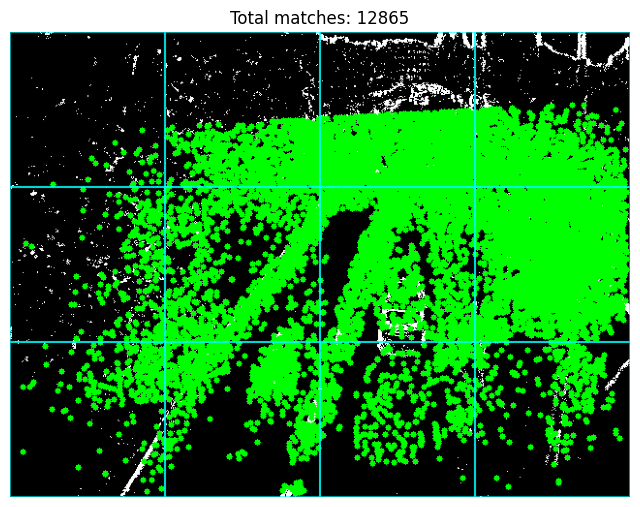

In [23]:
visualize_matches_on_event(event_img, pts0, pts1, H, mask, use_inliers=True)

In [ ]:
def matches_to_binary_mask(event_img, pts1, mask=None):
    h, w = event_img.shape[:2]

    # Initialize binary image
    binary = np.zeros((h, w), dtype=np.uint8)

    # Filter inliers if mask is provided
    if mask is not None:
        inlier_mask = mask.ravel().astype(bool)
        pts1 = pts1[inlier_mask]

    # Fill pixels
    for x, y in pts1:
        xi, yi = int(round(x)), int(round(y))
        if 0 <= xi < w and 0 <= yi < h:
            binary[yi, xi] = 1

    return binary

In [ ]:
matches_frame = matches_to_binary_mask(event_img, pts1, mask)
matches_entropy, matches_count = spatial_entropy(matches_frame, (3, 4))

In [ ]:
matches_entropy

0.9119938775318824

In [ ]:
avg_count = num_inliers/(3*4)

In [ ]:
matches_count/avg_count*100

array([      15.21,      36.261,      60.879,      32.467,      19.864,      60.962,      63.852,      31.413,     0.68783,       22.11,       22.31,      11.044])

In [22]:
label_path = Path(f"//172.16.222.2/tmp/Nora/traffic_flow_data/week_36/box_3/2024_09_10_15_50_59_recordings/labels/clip_000/{sel_idx}.txt")

In [413]:
data_000 = np.load("week_36/box_3/2024_09_10_15_50_59_recordings/homography.npz")
H_000 = data_000["H"].astype(np.float32)
data_030 = np.load("week_36/box_3/2024_09_10_15_50_59_recordings/homography_tst.npz")
H_030 = data_030["H"].astype(np.float32)

In [ ]:
# load first event frame
H2, W2 = spike_dict[sel_idx].shape[-2], spike_dict[sel_idx].shape[-1]
H1, W1 = frames[sel_idx].shape[-2], frames[sel_idx].shape[-1]

for s in label_path.read_text().splitlines():
    cls, x, y, w, h, conf = s.split()[:6]
    if float(conf) > 0.6:
        x, y, w, h = map(float, (x, y, w, h))

        # YOLO -> corners (pixels)
        x*=W2; y*=H2; w*=W2; h*=H2
        c = np.float32([[x-w/2,y-h/2],[x+w/2,y-h/2],[x+w/2,y+h/2],[x-w/2,y+h/2]]).reshape(-1,1,2)

        # warp corners, then axis-aligned bbox
        c_030 = cv2.perspectiveTransform(c, H_030).reshape(-1,2)
        c_000 = cv2.perspectiveTransform(c, H_000).reshape(-1,2)
        

plt.axis("off")
plt.show()

In [414]:
# load first event frame
H2, W2 = spike_dict[sel_idx].shape[-2], spike_dict[sel_idx].shape[-1]
H1, W1 = frames[sel_idx].shape[-2], frames[sel_idx].shape[-1]

all_corner_dists = []   # every corner from every label
label_mean_dists = []   # one mean distance per label
label_stats = []        # optional detailed storage

for s in label_path.read_text().splitlines():
    cls, x, y, w, h, conf = s.split()[:6]
    conf = float(conf)

    if conf <= 0.6:
        continue

    x, y, w, h = map(float, (x, y, w, h))

    # YOLO normalized -> pixel corners in spike image coordinates
    x *= W2
    y *= H2
    w *= W2
    h *= H2

    corners = np.float32([
        [x - w/2, y - h/2],  # top-left
        [x + w/2, y - h/2],  # top-right
        [x + w/2, y + h/2],  # bottom-right
        [x - w/2, y + h/2],  # bottom-left
    ]).reshape(-1, 1, 2)

    # Transform corners with each homography
    c_030 = cv2.perspectiveTransform(corners, H_030).reshape(-1, 2)
    c_000 = cv2.perspectiveTransform(corners, H_000).reshape(-1, 2)

    # Manhattan distance for each corresponding corner
    # shape: (4,)
    corner_dists = np.abs(c_030 - c_000).sum(axis=1)

    # store
    all_corner_dists.extend(corner_dists.tolist())
    label_mean_dists.append(corner_dists.mean())

    label_stats.append({
        "class": cls,
        "conf": conf,
        "corners_030": c_030,
        "corners_000": c_000,
        "corner_dists": corner_dists,
        "mean_dist": corner_dists.mean(),
        "std_dist": corner_dists.std(),
    })

# Overall stats across all corners of all labels
all_corner_dists = np.array(all_corner_dists, dtype=np.float32)
overall_mean = all_corner_dists.mean()
overall_std = all_corner_dists.std()

# Stats across labels (using per-label mean distance)
label_mean_dists = np.array(label_mean_dists, dtype=np.float32)
mean_of_label_means = label_mean_dists.mean()
std_of_label_means = label_mean_dists.std()

print(f"Overall corner Manhattan distance: mean={overall_mean:.3f}, std={overall_std:.3f}")
print(f"Per-label mean Manhattan distance: mean={mean_of_label_means:.3f}, std={std_of_label_means:.3f}")

# Optional: inspect each label
for i, st in enumerate(label_stats):
    print(
        f"label {i}: class={st['class']}, conf={st['conf']:.2f}, "
        f"mean={st['mean_dist']:.3f}, std={st['std_dist']:.3f}, "
        f"corner_dists={st['corner_dists']}"
    )

Overall corner Manhattan distance: mean=2.174, std=1.712
Per-label mean Manhattan distance: mean=2.174, std=1.617
label 0: class=2, conf=0.79, mean=0.633, std=0.070, corner_dists=[    0.71776     0.58142     0.54924     0.68536]
label 1: class=5, conf=0.95, mean=1.943, std=0.545, corner_dists=[      2.687      1.7361      1.2008      2.1462]
label 2: class=2, conf=0.93, mean=3.190, std=1.538, corner_dists=[     4.1275      1.3939      2.0399      5.1986]
label 3: class=0, conf=0.92, mean=4.252, std=0.646, corner_dists=[     3.6435      3.5702       4.909      4.8863]
label 4: class=2, conf=0.63, mean=2.497, std=0.722, corner_dists=[     2.9442       1.822      1.7733      3.4499]
label 5: class=2, conf=0.72, mean=1.508, std=0.130, corner_dists=[     1.6672      1.4156      1.3484      1.5998]
label 6: class=2, conf=0.91, mean=0.753, std=0.243, corner_dists=[    0.53799     0.79636      1.1329      0.5443]
label 7: class=1, conf=0.85, mean=6.916, std=0.658, corner_dists=[     7.3384    

In [31]:
# 1) Read video frames (grayscale) into a time stack [T, H, W]
cap = cv2.VideoCapture(video_path)
frames = []
t = 0

for _ in range(400 + 24*5400 + SHIFT):
    ret, frame = cap.read()
    if not ret:
        break

while True:
    ret, frame = cap.read()
    if not ret:
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)  # [H, W], values 0..255
    frames.append(gray)
    t += 1

    if t >= 6:
        break

cap.release()

In [57]:
data = torch.from_numpy(np.stack(frames, axis=0)).to(torch.float32)  # [T, H, W]
spikes_test = spikegen.delta(data[1:3], threshold=6)    

In [58]:
sp = spikes_test[1:].cpu().numpy() if torch.is_tensor(spikes) else spikes
frame_tst = (sp > 0).any(axis=0).astype(np.uint8)

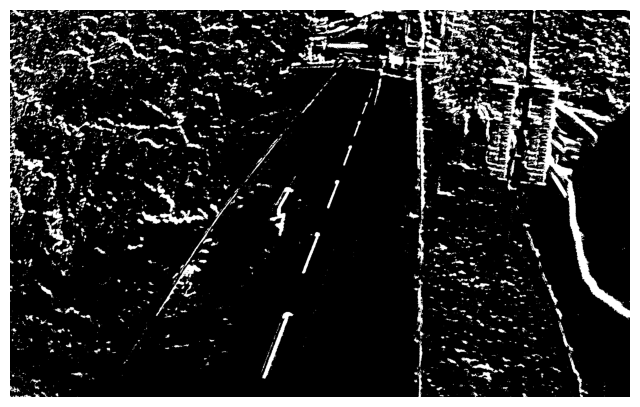

In [24]:
plt.figure(figsize=(8, 8))
plt.imshow(spike_dict[sel_idx], cmap='gray')
plt.axis("off")
plt.show()

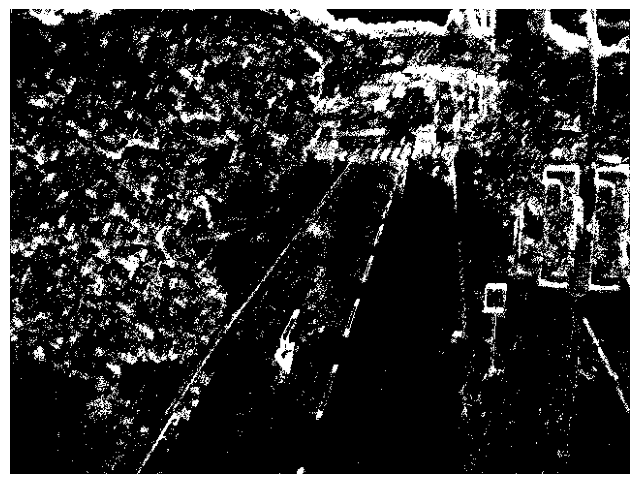

In [25]:
plt.figure(figsize=(8, 8))
plt.imshow(frames[sel_idx], cmap='gray')
plt.axis("off")
plt.show()

In [67]:
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {video_path}")

t = 0

while t < (SHIFT+sel_idx):
    ret, frame = cap.read()
    t += 1
ret, video_frame = cap.read()
cap.release()

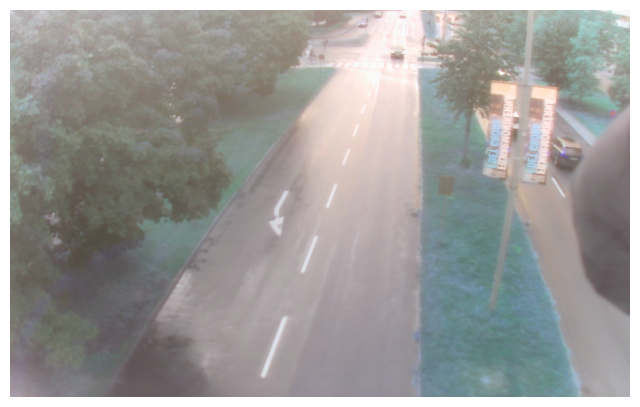

In [68]:
plt.figure(figsize=(8, 8))
plt.imshow(video_frame)
plt.axis("off")
plt.show()

In [26]:
def overlay_binary(frame_binary, overlay, H):

    warped = transform.warp(
        overlay.astype(np.float32),
        H,
        output_shape=frame_binary.shape,
        order=0, 
        preserve_range=True,
        cval=0.0
    )

    overlay_mask = warped > 0.5

    h, w = frame_binary.shape
    out = np.zeros((h, w, 3), dtype=np.uint8)

    out[frame_binary == 1] = [255, 255, 255]

    out[overlay_mask] = [255, 0, 0]

    return out

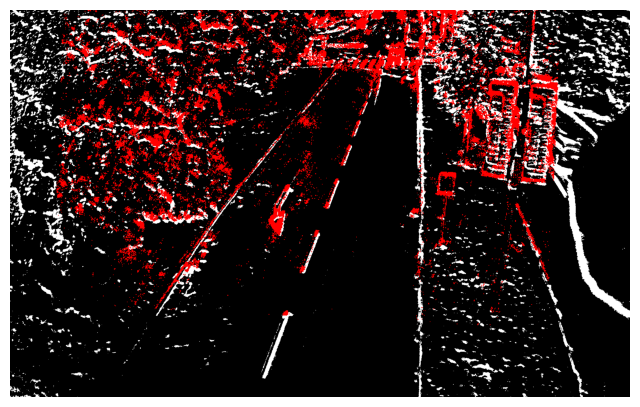

In [27]:
overlay = overlay_binary(spike_dict[sel_idx], frames[sel_idx], H)
plt.figure(figsize=(8, 8))
plt.imshow(overlay)   # overlay is HxWx3
plt.axis("off")
plt.show()

In [364]:
lightglue = {
    "extractor": "SuperPoint", # SuperPoint, DISK
    "device": "cpu", # cpu, cuda
    "max_kpts": 4096,
    "homography": {
        "method": cv2.RANSAC,
        "ransacReprojThreshold": 3.0
    }
}

In [365]:
def preprocess_lightglue(img):
    img = numpy_image_to_torch(img)
    return img


def match_lightglue(img0, img1, cfg):
    img0 = preprocess_lightglue(img0)
    img1 = preprocess_lightglue(img1)
    
    if cfg["extractor"] == "SuperPoint":
        extractor = SuperPoint(max_num_keypoints=cfg["max_kpts"]).eval().to(cfg["device"])
        matcher = LightGlue(features='superpoint').eval().to(cfg["device"])

    if cfg["extractor"] == "DISK":
        extractor = DISK(max_num_keypoints=cfg["max_kpts"]).eval().to(cfg["device"])  # load the extractor
        matcher = LightGlue(features='disk').eval().to(cfg["device"])  # load the matcher

    # extract local features
    feats0 = extractor.extract(img0)  # auto-resize the image, disable with resize=None
    feats1 = extractor.extract(img1)
    
    # match the features
    matches01 = matcher({'image0': feats0, 'image1': feats1})
    feats0, feats1, matches01 = [rbd(x) for x in [feats0, feats1, matches01]]  # remove batch dimension
    
    # get results
    kpts0 = feats0["keypoints"]
    kpts1 = feats1["keypoints"]
    matches = matches01['matches']  # indices with shape (K,2)
    points0 = kpts0[matches[..., 0]]  # coordinates in img0, shape (K,2)
    points1 = kpts1[matches[..., 1]]  # coordinates in img1, shape (K,2)
        
    return {
        "points0": points0,
        "points1": points1,
        "matches01": matches01, 
        "matches": matches,
        "kpts0": kpts0,
        "kpts1": kpts1,
        "img0": img0,
        "img1": img1
    }


def visualize_lightglue(img0, img1, points0, points1, kpts0, kpts1, matches01, **kwargs):
    axes = viz2d.plot_images([img0, img1], orientation='vertical')
    viz2d.plot_matches(points0, points1, color='lime', lw=0.2)
    # viz2d.add_text(0, f'Stop after {matches01["stop"]} layers', fs=20)

    kpc0, kpc1 = viz2d.cm_prune(matches01['prune0']), viz2d.cm_prune(matches01['prune1'])
    viz2d.plot_images([img0, img1])
    viz2d.plot_keypoints([kpts0, kpts1], colors=[kpc0, kpc1], ps=10)

In [366]:
%time results_lightglue = match_lightglue(proxy_img, event_img, lightglue)
visualize_lightglue(**results_lightglue)

CPU times: total: 48.4 s
Wall time: 6.56 s


TypeError: plot_images() got an unexpected keyword argument 'orientation'

In [377]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_lightglue_plt(img0, img1, points0, points1, kpts0, kpts1, matches01, **kwargs):
    # remove singleton dimension if present
    img0 = np.squeeze(img0)
    img1 = np.squeeze(img1)

    fig, axes = plt.subplots(2, 1, figsize=(6, 10))

    # grayscale if 2D
    if img0.ndim == 2:
        axes[0].imshow(img0, cmap="gray")
    else:
        axes[0].imshow(img0)

    if img1.ndim == 2:
        axes[1].imshow(img1, cmap="gray")
    else:
        axes[1].imshow(img1)

    for ax in axes:
        ax.axis("off")

    viz2d.plot_matches(points0, points1, color="lime", lw=0.3, axes=axes)

    kpc0 = viz2d.cm_prune(matches01["prune0"])
    kpc1 = viz2d.cm_prune(matches01["prune1"])
    viz2d.plot_keypoints([kpts0, kpts1], colors=[kpc0, kpc1], ps=10, axes=axes)

    plt.tight_layout()
    plt.show()

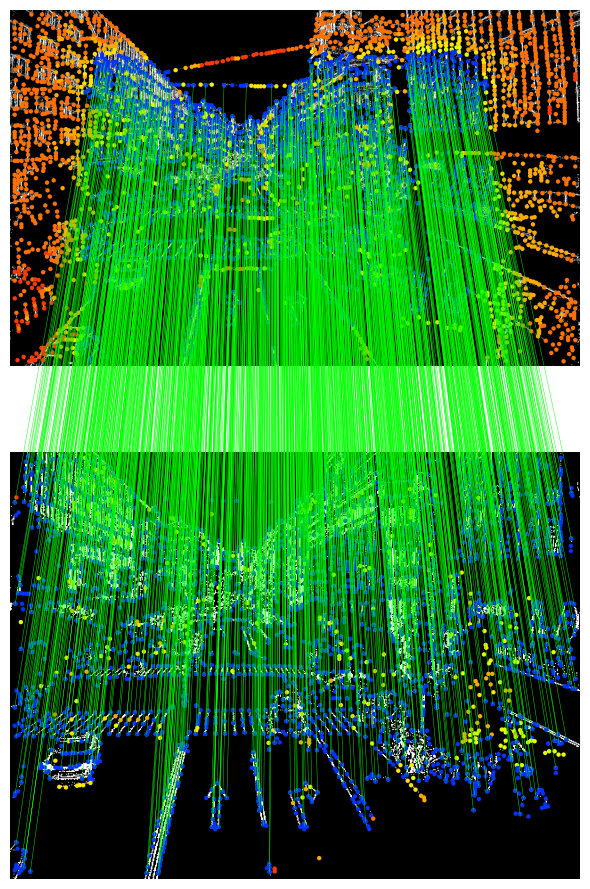

In [378]:
visualize_lightglue_plt(**results_lightglue)

In [ ]:
W2, H2 = video_frame.shape[1], video_frame.shape[0]         # frame size used when YOLO made the labels

# load first event frame
H1, W1 = frames[sel_idx].shape[-2], frames[sel_idx].shape[-1]

# make something viewable (binary image)
img = event_to_gray_uint8(frames[sel_idx])

# warp and draw boxes from frame onto event image
for s in label_path.read_text().splitlines():
    cls, x, y, w, h = s.split()[:5]
    x, y, w, h = map(float, (x, y, w, h))

    # YOLO -> corners (pixels)
    x*=W2; y*=H2; w*=W2; h*=H2
    c = np.float32([[x-w/2,y-h/2],[x+w/2,y-h/2],[x+w/2,y+h/2],[x-w/2,y+h/2]]).reshape(-1,1,2)

    # warp corners, then axis-aligned bbox
    c = cv2.perspectiveTransform(c, H).reshape(-1,2)
    x1,y1 = c.min(0); x2,y2 = c.max(0)
    x1,y1 = max(0,int(x1)), max(0,int(y1))
    x2,y2 = min(W1-1,int(x2)), min(H1-1,int(y2))

    cv2.rectangle(img, (x1,y1), (x2,y2), (0,0,255), 2)

cv2.imshow("Event frame with warped YOLO labels", img)
cv2.waitKey(0)
cv2.destroyAllWindows()

2 0.415613 0.479402 0.018871 0.026392 0.793417 173
5 0.264847 0.583263 0.069980 0.184451 0.947479 16
2 0.226838 0.925357 0.112766 0.145761 0.926065 13
0 0.823076 0.851984 0.030797 0.120836 0.918519 1115
2 0.220715 0.726439 0.072951 0.134772 0.631146 30
2 0.315175 0.519596 0.021969 0.035470 0.721659 25
0 0.574996 0.628844 0.015328 0.066888 0.574502 3
2 0.450703 0.566168 0.072640 0.051508 0.908360 1759
1 0.036340 0.715588 0.043806 0.051342 0.852872 1429
0 0.930942 0.873901 0.033500 0.120691 0.792048 1909
2 0.438923 0.511177 0.030826 0.036245 0.891320 1150
2 0.306888 0.576704 0.026914 0.050457 0.638810 19
7 0.413192 0.812156 0.173761 0.365123 0.872450 5
0 0.663847 0.603397 0.012681 0.050693 0.521086 1918
0 0.694254 0.646905 0.015015 0.060862 0.701166 2037
2 0.413166 0.449258 0.017386 0.021307 0.625074 1917
2 0.351796 0.536512 0.026597 0.041753 0.759442 2038
0 0.571967 0.543944 0.010029 0.041722 0.554722 1955
2 0.348813 0.470020 0.019185 0.026974 0.436514 1985
2 0.303131 0.534456 0.019685 

In [139]:
colors = {0: 'green', 1: 'red', 2: 'blue', 3: 'yellow', 5: 'orange', 7: 'red', 74:'purple'}

In [125]:
# YOLO labels mapping
yolo_labels = {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microwave', 69: 'oven', 70: 'toaster', 71: 'sink', 72: 'refrigerator', 73: 'book', 74: 'clock', 75: 'vase', 76: 'scissors', 77: 'teddy bear', 78: 'hair drier', 79: 'toothbrush'}

In [177]:
homography_path = "week_36/box_3/2024_09_10_15_50_59_recordings/homography.npz"
data = np.load(homography_path)
H = data["H"].astype(np.float32)
W1 = data["W1"]
H1 = data["H1"]
W2 = data["W2"]
H2 = data["H2"]

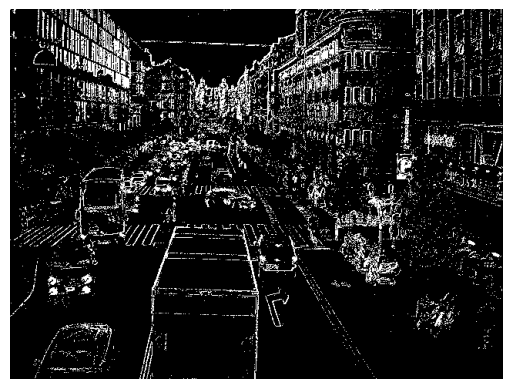

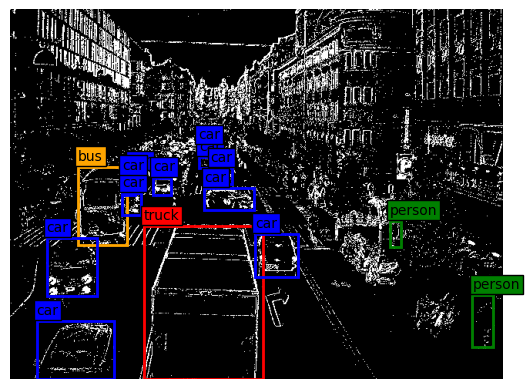

In [ ]:
img = event_to_gray_uint8(frames[sel_idx])
plt.axis("off")
plt.imshow(img, cmap='gray')

# Create figure and axes
fig, ax = plt.subplots(1)

# Display the image
ax.imshow(img, cmap='gray')

W2, H2 = video_frame.shape[1], video_frame.shape[0]         # frame size used when YOLO made the labels

# load first event frame
H1, W1 = frames[sel_idx].shape[-2], frames[sel_idx].shape[-1]

for s in label_path.read_text().splitlines():
    cls, x, y, w, h, conf = s.split()[:6]
    if float(conf) > 0.6:
        x, y, w, h = map(float, (x, y, w, h))

        # YOLO -> corners (pixels)
        x*=W2; y*=H2; w*=W2; h*=H2
        c = np.float32([[x-w/2,y-h/2],[x+w/2,y-h/2],[x+w/2,y+h/2],[x-w/2,y+h/2]]).reshape(-1,1,2)

        # warp corners, then axis-aligned bbox
        c = cv2.perspectiveTransform(c, H).reshape(-1,2)
        x1,y1 = c.min(0); x2,y2 = c.max(0)
        x1,y1 = max(0,int(x1)), max(0,int(y1))
        x2,y2 = min(W1-1,int(x2)), min(H1-1,int(y2))

        if 0 <= x1-10 and x1 + 20 <= W1:
            # Create a Rectangle patch
            rect = patches.Rectangle((x1, y1), (x2-x1), (y2-y1), linewidth=2, edgecolor=colors[int(cls)], facecolor="none")

            label = yolo_labels[int(cls)]

            ax.text(
                x1, y1 - 5,                
                label,
                color='black',
                fontsize=10,
                verticalalignment='bottom',
                bbox=dict(facecolor=colors[int(cls)], alpha=1, pad=2)
            )

            # Add the patch to the Axes
            ax.add_patch(rect)
plt.axis("off")
plt.show()

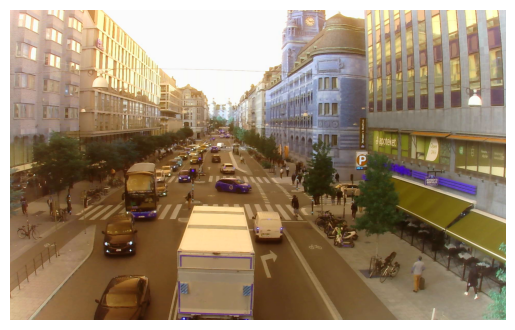

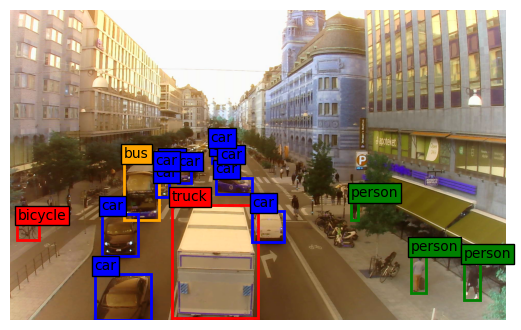

In [ ]:
plt.axis('off')
plt.imshow(video_frame)

# Create figure and axes
fig, ax = plt.subplots(1)

# Display the image
ax.imshow(video_frame)

W2, H2 = video_frame.shape[1], video_frame.shape[0]         # frame size used when YOLO made the labels

for s in label_path.read_text().splitlines():
    cls, x, y, w, h, conf = s.split()[:6]
    x, y, w, h = map(float, (x, y, w, h))

    if float(conf) > 0.6:
        x*=W2; y*=H2; w*=W2; h*=H2
        x1,y1 = x-w/2, y-h/2

        if 0 <= x1-10 and x1 + 50 <= W2:
            # Create a Rectangle patch
            rect = patches.Rectangle((x1, y1), w, h, linewidth=2, edgecolor=colors[int(cls)], facecolor="none")


            label = yolo_labels[int(cls)]

            ax.text(
                x1, y1 - 5,                
                label,
                color='black',
                fontsize=10,
                verticalalignment='bottom',
                bbox=dict(facecolor=colors[int(cls)], alpha=1, pad=2)
            )

            # Add the patch to the Axes
            ax.add_patch(rect)
plt.axis('off')
plt.show()

In [ ]:
from ultralytics import YOLO
import matplotlib.patches as patches
model = YOLO("yolo26x.pt")
results = model(frame, conf=0.1, verbose=False)[0]

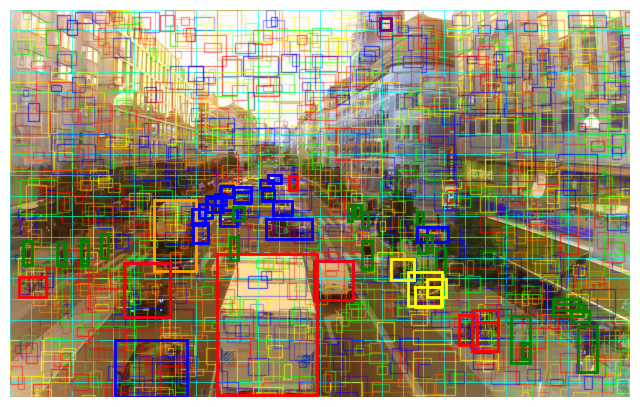

In [174]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

H, W = frame.shape[:2]

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(frame)

class_colors = {
    0: (1, 0, 0),
    1: (0, 1, 0),
    2: (0, 0, 1),
    3: (1, 1, 0),
    4: (1, 0.5, 0)
}


grid_stride = 64

for y in range(0, H, grid_stride):
    for x in range(0, W, grid_stride):
        rect = patches.Rectangle(
            (x, y),
            grid_stride,
            grid_stride,
            linewidth=0.5,
            edgecolor=(0, 1, 1, 0.6),
            facecolor='none'
        )
        ax.add_patch(rect)


for stride in [8, 16, 32]:
    for y in range(0, H, stride):
        for x in range(0, W, stride):

            if np.random.rand() > 0.05:
                continue

            cls = np.random.randint(0, 5)
            conf = np.random.rand()

            if conf < 0.4:
                continue

            w = stride * np.random.uniform(2, 8)
            h = stride * np.random.uniform(2, 8)

            rect = patches.Rectangle(
                (x, y),
                w,
                h,
                linewidth=1,
                edgecolor=(*class_colors[cls], conf * 0.6),
                facecolor='none'
            )
            ax.add_patch(rect)

for box in results.boxes:
    cls = int(box.cls.item())
    conf = float(box.conf.item())
    x, y, w, h = box.xywhn[0].tolist()

    x*=W2; y*=H2; w*=W2; h*=H2
    x1,y1 = x-w/2, y-h/2
        
    rect = patches.Rectangle((x1, y1), w, h, linewidth=2, edgecolor=colors.get(int(cls), "green"), facecolor="none")

    ax.add_patch(rect)

ax.axis('off')

plt.show()

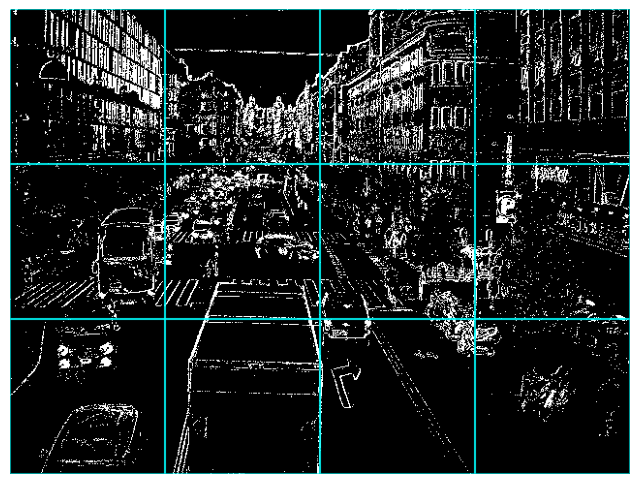

In [278]:
H2, W2 = frames[sel_idx].shape[:2]

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(frames[sel_idx], cmap='gray')
n = 3
w = int(W2/(n+1))
h = int(H2/n)

for y in range(0, H2, h):
    for x in range(0, W2, w):
        rect = patches.Rectangle(
            (x, y),
            w,
            h,
            linewidth=1.5,
            edgecolor=(0, 1, 1, 0.6),
            facecolor='none'
        )
        ax.add_patch(rect)

ax.axis('off')

plt.show()